# 2.4 真实 Auto 项目与综合练习

原始数据来自 https://www.statlearning.com/s/Auto.data ，说明：https://intro-stat-learning.github.io/ISLP/datasets/Auto.html 。以Notebook所在目录为工作目录，从头运行。配套包带数据，单独下载Notebook则首次运行需要联网。固定候选与划分后，测试结果仅用于最终报告。

### 代码2.4-01：准备环境与项目目录

Notebook 放在“代码/第二章”，以该目录为工作目录。数据、图片和结果分别保存在三个子目录。这里导入的工具沿用前面已学的数组、表格、绘图与划分接口。

### 逐步读代码

- `Path`管理路径，`hashlib`计算文件校验值，`json`负责结构化报告；`np`、`pd`、`plt`分别是数组、表格与绘图工具。

- `train_test_split`负责成对划分输入目标，`mean_squared_error`计算预测误差；这里只导入，还没有训练或评估。

- 三个`Path`分别指向数据、图片和结果目录。`for folder in [...]`让同一个变量依次指向三个路径，缩进的`mkdir(exist_ok=True)`为它们创建目录，目录已存在也可继续。

In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

data_dir = Path("数据")
image_dir = Path("图片")
result_dir = Path("结果")
for folder in [data_dir, image_dir, result_dir]:
    folder.mkdir(exist_ok=True)


### 代码2.4-02：定位官方数据并记录校验值

配套包已含原始数据；单独下载Notebook时，文件不存在才从官网获取。校验值标识本次使用的文件版本，便于别人核对数据是否一致；它不是预测模型的参数。

### 逐步读代码

- `source_url`保存网址字符串；`data_dir / "Auto.data"`把目录与文件名拼成路径，`/`在这里不是数值除法。

- `.exists()`判断路径是否存在；`not`把真假取反。只有本地文件不存在时才进入`if`下载，避免重复覆盖已有数据。

- `with urlopen(...,timeout=30) as response:`打开网络响应并命名为`response`；`with`结束时会关闭资源。`timeout`限制网络操作等待，失败会报错，不会凭空生成数据。

- `response.read()`取得字节内容，`write_bytes`写到磁盘。随后`read_bytes()`读取本地文件，`sha256(...).hexdigest()`生成十六进制校验字符串，用于核对文件是否相同，不是验证数据一定正确。

In [3]:
from urllib.request import urlopen

source_url = "https://www.statlearning.com/s/Auto.data"
data_path = data_dir / "Auto.data"
if not data_path.exists():
    with urlopen(source_url, timeout=30) as response:
        data_path.write_bytes(response.read())
data_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
print(data_sha256)


5fffe32212d7f8f82749e0a9c95a747215921c120257fcf3ab5bcb16757e0ba6


### 代码2.4-03：读取字段、类型和缺失数量

该文件使用空白分隔，不是逗号分隔，所以使用正则表达式 `sep=r"\textbackslash s+"`。问号按缺失处理。此时只核对结构与缺失，不画全体数据的目标关系图来挑模型。

### 逐步读代码

- `pd.read_csv`也能读其他分隔符的文本；`sep=r"\s+"`用正则表达式表示一个或多个空白字符，前缀`r`让反斜杠按原样交给解析器。

- `na_values=["?"]`把问号识别为缺失。`auto.shape`报告整表行列数，`auto.dtypes`逐列报告类型。

- `auto.isna()`产生缺失位置布尔表；`.sum()`默认沿样本轴按列计数，因此输出的是每列缺失数，不是每辆车缺几项。

In [4]:
auto = pd.read_csv(data_path, sep=r"\s+", na_values=["?"])
print(auto.shape)
print(auto.dtypes)
print(auto.isna().sum())


(397, 9)
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
year              int64
origin            int64
name             object
dtype: object
mpg             0
cylinders       0
displacement    0
horsepower      5
weight          0
acceleration    0
year            0
origin          0
name            0
dtype: int64


### 代码2.4-04：按预定规则保留完整记录

这是固定的完整记录规则，没有从全体目标值学习阈值或填补参数。它改变了研究对象：结论只适用于完整记录。若缺失原因与车辆特征或mpg有关，删行后的样本可能有选择偏差。

### 逐步读代码

- `feature_columns`是输入列名列表，`target_column`是目标列名字符串；`[target_column]`把字符串包为列表，`+`连接后得到要检查的三列。

- `auto.dropna(subset=required)`删除这三列中任一列缺失的行；`.copy()`保存副本，不改原始`auto`。先统一筛选整表，再拆出`X`和`y`，避免样本错位。

- 用列表选列得到二维DataFrame，用字符串选一列得到一维Series。`len(auto)`、`len(X)`和它们的差分别是原始、保留、删除的行数；形状输出应为`(392,2)`与`(392,)`。

- `assert 条件`称为断言：条件为真时安静通过；为假时抛出`AssertionError`并停止当前单元格。`X.index.equals(y.index)`比较两组行标签及其排列顺序，核对特征与目标是否对齐。

- `X.notna()`把非缺失位置变为真；第一次`.all()`检查每一列是否全部为真，得到按列排列的Series；第二次`.all()`再检查所有列，得到一个布尔值。

- `y`只有一维，所以`y.notna().all()`一次即可汇总。`and`要求输入和目标两边都通过；缺失检查不能证明数值单位正确或没有无穷值。断言用于开发核对，不能替代生产程序必需的输入校验。

In [5]:
feature_columns = ["horsepower", "weight"]
target_column = "mpg"
required = feature_columns + [target_column]
clean_auto = auto.dropna(subset=required).copy()
X = clean_auto[feature_columns]
y = clean_auto[target_column]
print("raw, complete, removed:", len(auto), len(X), len(auto)-len(X))
print(X.shape, y.shape)
assert X.index.equals(y.index)
assert X.notna().all().all() and y.notna().all()


raw, complete, removed: 397 392 5
(392, 2) (392,)


### 代码2.4-05：划分并保存样本身份

训练、验证、测试为234、79、79行。小数比例需要落实为整数行，不能机械地写成235、78、79。保存行标签后，可以检查各次实验是否使用同一份划分。固定随机种子用于复现，不代表该划分是最优的。

### 逐步读代码

- 第一次划分留下20%作测试，其余作开发；第二次在开发集中留25%作验证。小数比例由工具转换为整数行，结果是234、79、79。

- `random_state`固定各次随机过程；两个不同种子42和24分别对应两次划分，不是模型参数。

- `set(...).isdisjoint(...)`检查行标签集合是否无交集，`assert`在有交集时使单元格报错。这里原始行索引唯一，适合用来追踪记录。

- `pd.Series("train",index=...,name="split")`先给全部完整记录贴上train标签；`split.loc[...] = ...`再按验证、测试行标签修改对应值。

- `to_csv`保存划分表，`index_label="row_id"`给写出的索引列命名，便于别人复现同一组样本，而不是只复现大致比例。

In [6]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=24
)
print("train, validation, test:", len(X_train), len(X_val), len(X_test))
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
split = pd.Series("train", index=clean_auto.index, name="split")
split.loc[X_val.index] = "validation"
split.loc[X_test.index] = "test"
split.to_csv(result_dir / "auto_split.csv", index_label="row_id")


train, validation, test: 234 79 79


### 代码2.4-06：查看训练集的数值范围

只查看训练数据的均值、标准差与范围。这里的 `std` 仍采用pandas默认的 $n-1$ 分母。检查单位和范围是否符合数据含义；不因为某个值看起来极端就随意删除。

### 逐步读代码

- `X_train.copy()`复制训练特征表；随后增加mpg列。把Series赋给DataFrame列时，pandas按索引标签对齐，因此这里使用配对划分得到的`y_train`。

- `describe()`汇总各列的计数、均值、标准差和分位数；`.round(2)`只为打印生成两位小数版本。原训练数据没有因此舍入。

In [7]:
train_table = X_train.copy()
train_table["mpg"] = y_train
print(train_table.describe().round(2))


       horsepower   weight     mpg
count      234.00   234.00  234.00
mean       108.11  3058.40   22.92
std         40.04   856.83    7.96
min         46.00  1613.00    9.00
25%         78.50  2291.25   16.12
50%         97.00  2931.50   21.25
75%        137.75  3728.75   28.95
max        230.00  5140.00   46.60


### 代码2.4-07：观察训练数据的关系

两个绘图区依次画马力与mpg、重量与mpg。`zip` 把绘图区与列名一一配对。观察整体趋势、弯曲和离散程度；图中关联不能解释为减轻重量必然造成同样幅度的油耗改善。候选方法已经预先固定，不根据测试图形反复调整。

### 逐步读代码

- `subplots(1,2)`创建一行两张图，`axes`是一维绘图区数组。`zip(axes,feature_columns)`把第一个图区配马力、第二个配重量。

- 循环每轮将一对对象解包给`ax, feature`；`X_train[feature]`取当前输入列，`y_train`提供纵坐标。

- `s=17`控制点面积，`alpha=0.6`让重叠点更容易辨认；轴名随当前特征改变。循环之后才对整张图调整布局、保存、显示并关闭。

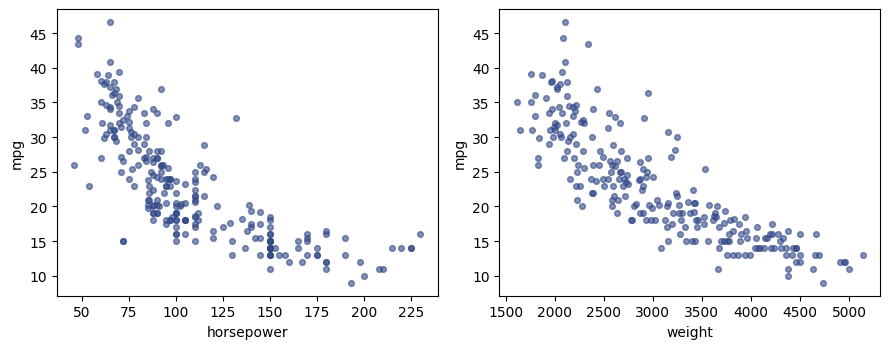

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, feature in zip(axes, feature_columns):
    ax.scatter(X_train[feature], y_train, s=17, alpha=0.6,
               color="#314887")
    ax.set_xlabel(feature)
    ax.set_ylabel("mpg")
fig.tight_layout()
fig.savefig(image_dir / "240-train-scatter.pdf")
fig.savefig(image_dir / "240-train-scatter.png", dpi=180)
display(fig)
plt.close(fig)


### 代码2.4-08：用统一接口定义三个模型

`DummyRegressor` 学习训练目标的均值，与上一实验的手工基准相同。`make_pipeline` 按顺序串联标准化和KNN；对整个流水线调用fit时，先在训练数据拟合标准化参数，再拟合KNN。线性回归沿用原始单位，以便解释系数。

### 逐步读代码

- `models`是“方法名称→模型对象”的字典；冒号左边的字符串用于识别方法，右边创建相应对象。

- `DummyRegressor(strategy="mean")`在fit时学习目标均值；`LinearRegression()`学习线性系数；KNN的`n_neighbors=5`固定取五位邻居。

- `make_pipeline(StandardScaler(), KNeighborsRegressor(...))`按顺序连接预处理与模型。对整体调用fit会先学习训练均值、标准差并转换输入，再拟合KNN；predict会自动使用同一套转换。

- 此时只是定义三种候选，没有读取验证或测试目标来决定参数。

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

models = {
    "baseline": DummyRegressor(strategy="mean"),
    "linear": LinearRegression(),
    "knn5": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=5)
    ),
}


### 代码2.4-09：逐个训练并比较验证误差

循环使用相同的训练与验证样本，表中两列分别回答“对已学样本拟合得如何”和“对未用于拟合的验证样本预测得如何”。`mean_squared_error` 与手写平方差均值相同；这里还没有调用测试集进行模型比较。

### 逐步读代码

- `rows=[]`先创建空列表；`models.items()`每次返回一个“名称、对象”对，由`name, candidate`接收。

- 每轮先在同一训练数据上fit，再分别预测训练与验证输入。`mean_squared_error(真实值,预测值)`返回一个MSE标量，输入必须按相同样本顺序对应。

- `rows.append({...})`把本轮名称与两个误差组成字典追加到列表末尾；三轮后列表有三条记录。

- `pd.DataFrame(rows)`把记录变为表，`.set_index("model")`把方法名设为行标签，便于后面按名称选模型。打印时保留四位小数，CSV保存表中原数值。

In [10]:
rows = []
for name, candidate in models.items():
    candidate.fit(X_train, y_train)
    train_pred = candidate.predict(X_train)
    val_pred = candidate.predict(X_val)
    rows.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, train_pred),
        "validation_mse": mean_squared_error(y_val, val_pred),
    })
scores = pd.DataFrame(rows).set_index("model")
print(scores.round(4))
scores.to_csv(result_dir / "auto_validation_scores.csv")


          train_mse  validation_mse
model                              
baseline    63.1285         64.8289
linear      17.2759         20.3014
knn5        11.0711         24.2467


### 代码2.4-10：固定选择并检查训练参数

`idxmin()` 返回验证误差最小的行名。这里顺便核对KNN流水线的标准化参数确实等于训练集统计量。验证数据只影响方法选择，不参与这一步均值或标准差的拟合。

### 逐步读代码

- `scores["validation_mse"]`取验证误差列；`.idxmin()`返回最小值所在的行标签，也就是方法名，不是最小误差值。并列时取当前顺序中的第一个。

- `models["knn5"]`从字典取KNN流水线；`.named_steps["standardscaler"]`再从步骤映射中取标准化器。这个步骤名由`make_pipeline`生成。

- `.mean_`与`.scale_`是已经fit得到的训练均值和缩放尺度；末尾下划线提示这是拟合后属性。

- `np.allclose(a,b)`允许浮点误差，在默认容差内逐项比较两组数并汇总成真假；外层`assert`要求比较通过。这里用`ddof=0`与StandardScaler的标准差定义保持一致。

- 检查KNN的预处理是否正确，与最终是否选中KNN是两回事；本次验证选择的是线性回归。

In [11]:
chosen_name = scores["validation_mse"].idxmin()
print("chosen:", chosen_name)
print("training target mean:", y_train.mean())
scaler = models["knn5"].named_steps["standardscaler"]
print("scaler mean:", scaler.mean_)
print("scaler scale:", scaler.scale_)
assert np.allclose(scaler.mean_, X_train.mean().to_numpy())
assert np.allclose(scaler.scale_, X_train.std(ddof=0).to_numpy())


chosen: linear
training target mean: 22.922649572649576
scaler mean: [ 108.10683761 3058.4017094 ]
scaler scale: [ 39.95373013 854.99762643]


### 代码2.4-11：在开发集上重新拟合选定方法

`clone` 保留方法和超参数，创建一个尚未拟合的新对象，不沿用旧训练状态。然后在313行开发数据上重新拟合。如果选中KNN，标准化也会在开发集重新学习；这些行为是在测试前固定的。

### 逐步读代码

- `models[chosen_name]`按已选方法名取出模型；`clone`复制其类型和超参数，但不复制已学习的训练状态。

- 对新对象调用`fit(X_dev,y_dev)`，在全部313行开发数据上重新学习。若模型包含预处理，预处理也随整个流水线重训。

- 两次打印确认方法名称和实际重训行数，不能据测试结果再改变`chosen_name`。

In [12]:
from sklearn.base import clone

final_model = clone(models[chosen_name])
final_model.fit(X_dev, y_dev)
print("fixed method:", chosen_name)
print("development rows:", len(X_dev))


fixed method: linear
development rows: 313


### 代码2.4-12：计算最终测试指标

RMSE是MSE的平方根，恢复到mpg单位；MAE是绝对误差的均值。本次选择指标始终是验证MSE，另外两项只帮助解释最终结果。基准是事先约定的固定参照，此处不评估所有候选后重新选择。若最终方法输给基准，也应如实报告。

### 逐步读代码

- `final_model.predict(X_test)`生成最终预测；`mean_squared_error`得到MSE，`np.sqrt`开平方得到RMSE。

- `np.abs(y_test.to_numpy()-final_pred)`逐项取绝对误差，再求均值得MAE。使用相同顺序的一维数组，避免索引或广播造成误算。

- `DummyRegressor(...).fit(...)`把创建和拟合连写；fit返回拟合后的对象，于是`baseline_final`可以直接predict。基准也只使用开发目标学习。

- `round(数值,4)`用于打印四位小数，不改原指标。这一块只报告固定方案及事先约定的基准，不在测试结果中重新挑选候选。

In [13]:
final_pred = final_model.predict(X_test)
test_mse = mean_squared_error(y_test, final_pred)
test_rmse = np.sqrt(test_mse)
test_mae = np.mean(np.abs(y_test.to_numpy() - final_pred))
baseline_final = DummyRegressor(strategy="mean").fit(X_dev, y_dev)
baseline_test_pred = baseline_final.predict(X_test)
baseline_test_mse = mean_squared_error(y_test, baseline_test_pred)
print("selected test MSE:", round(test_mse, 4))
print("selected test RMSE:", round(test_rmse, 4))
print("selected test MAE:", round(test_mae, 4))
print("fixed baseline test MSE:", round(baseline_test_mse, 4))


selected test MSE: 17.7918
selected test RMSE: 4.218
selected test MAE: 3.5057
fixed baseline test MSE: 51.6203


### 代码2.4-13：保存逐车预测与残差

保留原行号与车型名便于追踪，模型输入仍只有马力和重量。正残差表示低估，负残差表示高估。完整表写入CSV，书中只展示前五行，不用少数样本代替整体评价。

### 逐步读代码

- 字典中的`name`按测试行标签从完整表取车型名，`actual`保存真实目标，`predicted`保存预测数组；`index=X_test.index`规定结果表的行身份和顺序。

- 带索引的Series按标签对齐；没有索引的预测数组按位置填入。因此预测必须来自这份同顺序的`X_test`，不能随意打乱。

- 新增`residual`列是实际值减预测值。双层方括号按指定顺序选三列，`head()`只看前五行，`round(3)`只简化显示。

- `to_csv(...,index_label="row_id")`保存完整结果及原行标签，便于追踪每辆车，而不仅保存屏幕上的五行。

In [14]:
test_results = pd.DataFrame({
    "name": clean_auto.loc[X_test.index, "name"],
    "actual": y_test,
    "predicted": final_pred,
}, index=X_test.index)
test_results["residual"] = (
    test_results["actual"] - test_results["predicted"]
)
print(test_results[["actual", "predicted", "residual"]].head().round(3))
test_results.to_csv(result_dir / "auto_test_predictions.csv",
                    index_label="row_id")


     actual  predicted  residual
79     26.0     30.136    -4.136
276    21.6     24.179    -2.579
248    36.1     32.889     3.211
56     26.0     31.458    -5.458
392    27.0     25.721     1.279


### 代码2.4-14：画最终测试诊断图

左图越接近对角线，预测越接近实际；右图帮助识别误差方向和分布。现在模型已经固定，图形用于报告局限。若据图再改模型，就开启了新一轮开发，需要新的独立评估设计，不能继续把同一测试结果当作未见数据成绩。

### 逐步读代码

- 左图画实际值对预测值。`min`在两组最小值中取更小者，`max`在最大值中取更大者，组合成覆盖两轴数据的`limits`。

- `plot(limits,limits,"--")`连接两个坐标相同的端点，画出理想预测线y=x；`set(xlabel=...,ylabel=...)`一次设置两个轴名。

- 右图横轴是预测值，纵轴是残差；`axhline(0)`标出零残差线。图形用来报告已固定方案的误差结构，不参与这一轮重新调参。

- 最后对整图调整留白，保存PDF和PNG，显示并关闭绘图对象。

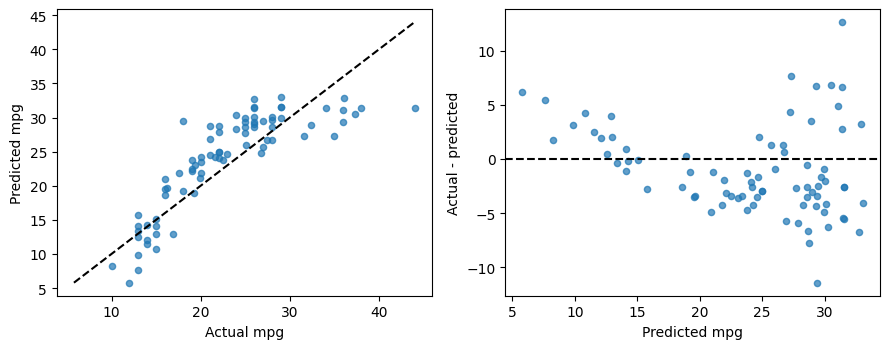

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(y_test, final_pred, s=20, alpha=0.7)
limits = [min(y_test.min(), final_pred.min()),
          max(y_test.max(), final_pred.max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set(xlabel="Actual mpg", ylabel="Predicted mpg")
axes[1].scatter(final_pred, test_results["residual"], s=20, alpha=0.7)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted mpg", ylabel="Actual - predicted")
fig.tight_layout()
fig.savefig(image_dir / "240-test-diagnostics.pdf")
fig.savefig(image_dir / "240-test-diagnostics.png", dpi=180)
display(fig)
plt.close(fig)


### 代码2.4-15：给一辆待查询汽车生成预测

新表必须使用相同列名、列顺序和单位。预测值不是保证值，也不是置信区间。即使单个特征落在训练范围内，这个联合组合仍可能缺少相似样本；用于现代混合动力或电动车时还会面临分布变化和指标口径差异。

### 逐步读代码

- 每个字典值用单元素列表包住，让DataFrame建立一行两列；列名、顺序和单位与训练时一致。

- `predict`返回长度1的数组，`np.round(...,3)`只用于显示。这里没有新车真实mpg，因而只能生成预测，不能计算这辆车的实际误差。

In [16]:
new_car = pd.DataFrame({"horsepower": [100.0], "weight": [3000.0]})
new_prediction = final_model.predict(new_car)
print("predicted mpg:", np.round(new_prediction, 3))


predicted mpg: [23.757]


### 代码2.4-16：导出可复现的项目报告

报告记录数据来源、文件校验值、特征、划分、选定方法与最终指标。连同Notebook中的环境版本、验证表和逐车预测，别人可以重跑核对。仅保存一个“最优分数”，不足以复现项目。

### 逐步读代码

- `report`用字典把数据来源、特征、样本数、种子和指标组织成“字段名→值”。这些字段让别人知道分数怎样产生。

- `float(...)`把库返回的数值显式转成Python浮点数，便于JSON序列化；它不会进行新的训练或估计。

- `json.dumps(report,indent=2)`把字典转换为带两空格缩进的字符串；`write_text(...,encoding="utf-8")`才把它写入文件。两步分别负责格式转换与磁盘写入。

- `.as_posix()`把路径显示成使用正斜杠的文字；打印Saved只报告保存位置，不代表另外做了模型验证。

In [17]:
report = {
    "source": source_url, "sha256": data_sha256,
    "features": feature_columns, "target": target_column,
    "n_raw": len(auto), "n_complete": len(clean_auto),
    "n_train": len(X_train), "n_validation": len(X_val),
    "n_test": len(X_test), "seeds": [42, 24],
    "selected_method": chosen_name,
    "test_mse": float(test_mse), "test_rmse": float(test_rmse),
    "test_mae": float(test_mae),
    "baseline_test_mse": float(baseline_test_mse),
}
report_path = result_dir / "auto_report.json"
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
print("Saved:", report_path.as_posix())


Saved: 结果/auto_report.json


## 练习2.42 均值基准为什么合理？

对已给定的 $n\ge1$ 个训练目标，考虑常数预测 $c$。严格证明训练平方误差在 $c=\bar y$ 时最小。

**参考答案**

令 $\bar y=\frac1n\sum_i y_i$。先写 $y_i-c=(y_i-\bar y)+(\bar y-c)$，逐项平方并求平均：

$$\begin{aligned}
\frac1n\sum_i(y_i-c)^2
&=\frac1n\sum_i(y_i-\bar y)^2
+\frac{2(\bar y-c)}n\sum_i(y_i-\bar y)
+(\bar y-c)^2.\end{aligned}$$

因为 $\sum_i(y_i-\bar y)=\sum_i y_i-n\bar y=0$，中间项为零。第一项与 $c$ 无关，最后一项非负，且仅当 $c=\bar y$ 为零，故这是唯一最小值。这个结论针对训练目标；不能为了降低测试误差而用测试均值生成预测。

## 练习2.43 从概率到有代价的决策

某客户购买概率为 $p=0.4$。错误联系不购买客户的代价为1，漏掉购买客户的代价为4，正确决策代价为0。应联系还是不联系？推导一般阈值。

**参考答案**

联系的条件期望损失是 $1(1-p)$，不联系的是 $4p$。当 $1-p<4p$，即 $1<5p$，也就是 $p>0.2$ 时应联系。本题两者分别为0.6与1.6，所以联系。条件期望是因为我们已经知道当前客户的特征，要比较该特征下的不确定结果。阈值0.5只适用于两类错误代价相同的情况。

## 练习2.44 偏差较小就一定更好吗？

固定输入处不可约误差方差为1。模型A的偏差为1、方差为0.5；模型B的偏差为0.2、方差为2。比较期望平方预测误差，并说明这个结论能否保证每批测试数据都如此。

**参考答案**

按此前证明的分解，A为 $1^2+0.5+1=2.5$，B为 $0.2^2+2+1=3.04$，所以A的期望误差更小。B的偏差优势不足以抵消方差增加。这里的期望涉及训练数据和新观测的随机性，有限测试样本误差会波动，不能保证每一批都由A获胜。

## 练习2.45 查找数据泄露

有人先对全表标准化，再划分训练、测试；用测试MSE挑选 $K$；最后报告同一测试MSE。指出两处问题，并给出可操作的修正。

**参考答案**

第一处是预处理从测试特征获得了均值与标准差；第二处是测试目标参与了超参数选择。应先划出最终测试集，开发集再分训练与验证。每个候选流水线只在训练数据fit，在验证数据比较 $K$。固定 $K$ 后用开发集重新fit整个流水线，最后在测试集评估。不能仅把变量名从test改成validation就获得新的独立测试数据。

## 练习2.46 模型边界与业务场景

本项目的线性回归、KNN和均值基准分别有什么长处与短处？如果平台要预测下一代电动车，应直接使用本项目吗？

**参考答案**

均值基准简单稳定、便于建立最低参照，但忽略个体特征。线性回归计算便宜、系数易检查，但线性关系不足时会产生结构性误差，相关特征也会影响系数稳定性。KNN可描述局部非线性，但依赖距离、尺度与邻居数量，稀疏区域不可靠，训练范围外的外推能力弱。历史燃油汽车的mpg模型不能直接作为下一代电动车模型；需要重新定义指标、取得代表性数据并按部署目标验证。

## 练习2.47 形状正确还不够

$X$ 和 $y$ 都有100行，是否就能安全训练？若 $y$ 为 $(100,1)$、预测为 $(100,)$，直接相减会得到什么？

**参考答案**

行数相同不保证样本身份和顺序相同。应先统一处理表格并核对索引，或使用同一组行索引划分。后面的减法可能广播成 $(100,100)$，产生所有两两差。单目标回归在相减前应统一为 $(100,)$，并确认每个预测对应同一个真实样本。

## 练习2.48 缺失、离群值与评估对象

马力缺失的五行删掉后，还能声称结果适用于所有汽车吗？箱线图标出的高mpg记录是否应直接删除？

**参考答案**

删行把评估对象限制到完整记录，缺失机制不同可能带来选择偏差，不能自动推广到缺失样本。若业务必须支持缺失输入，需要设计训练集内拟合的填补与相应评估。高mpg可能是有效记录，应检查来源、单位和事实。不能因为删除它会降低测试MSE就删掉，否则测试答案参与了数据与模型设计。

## 练习2.49 完成一份可审查的项目报告

请列出别人复现本项目所需的信息，并说明“测试RMSE为若干mpg”不意味着什么。

**参考答案**

至少包括问题与目标人群、数据来源和版本、特征与单位、清洗规则、划分行号与随机种子、候选方法和预处理、选择指标、验证结果、重训策略、最终测试结果及局限。RMSE不是每辆车误差的上界，也不表示某辆新车的置信区间；平均误差小仍可能掩盖部分车辆的大误差。单次随机划分也不能承诺未来分布上的同样表现。